/tmp/ipykernel_12139/3320499848.py:8: DtypeWarning: Columns (85: SimillarHTTP) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../dataset.csv")


           label  count
0   ddos_udp_lag   5986
1      ddos_snmp   5984
2      ddos_ssdp   5970
3      ddos_ldap   5928
4     ddos_mssql   5911
5       ddos_udp   5876
6   ddos_netbios   5830
7         benign   5658
8       ddos_syn   5480
9       ddos_dns   5369
10     ddos_tftp   5261
11      ddos_ntp    986


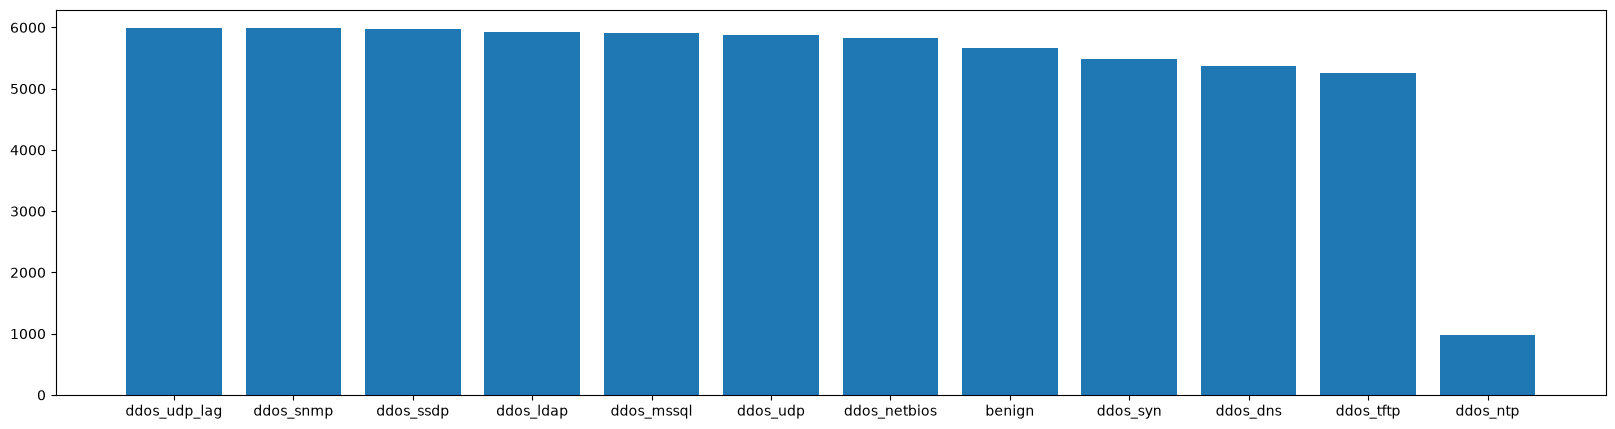

In [121]:
import pandas as pd
import numpy as np
import sklearn.preprocessing as skp
import sklearn.decomposition as skpca
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset.csv")

df_label = df['label'].value_counts().reset_index()
print(df_label)

plt.figure(figsize=(20,5))
plt.bar(x=df_label['label'],height=df_label['count'])
plt.show()

 Fwd_Packet_Length_Max ,  Fwd_Packet_Length_Min ,  Fwd_Packet_Length_Mean ,  Fwd_Packet_Length_Std ,                
   Bwd_Packet_Length_Max ,  Bwd_Packet_Length_Min ,  Bwd_Packet_Length_Mean ,  Bwd_Packet_Length_Std ,                
   Min_Packet_Length ,  Max_Packet_Length ,  Packet_Length_Mean ,  Packet_Length_Std ,  Packet_Length_Variance ,      
   Average_Packet_Size ,  Avg_Fwd_Segment_Size ,  Avg_Bwd_Segment_Size 

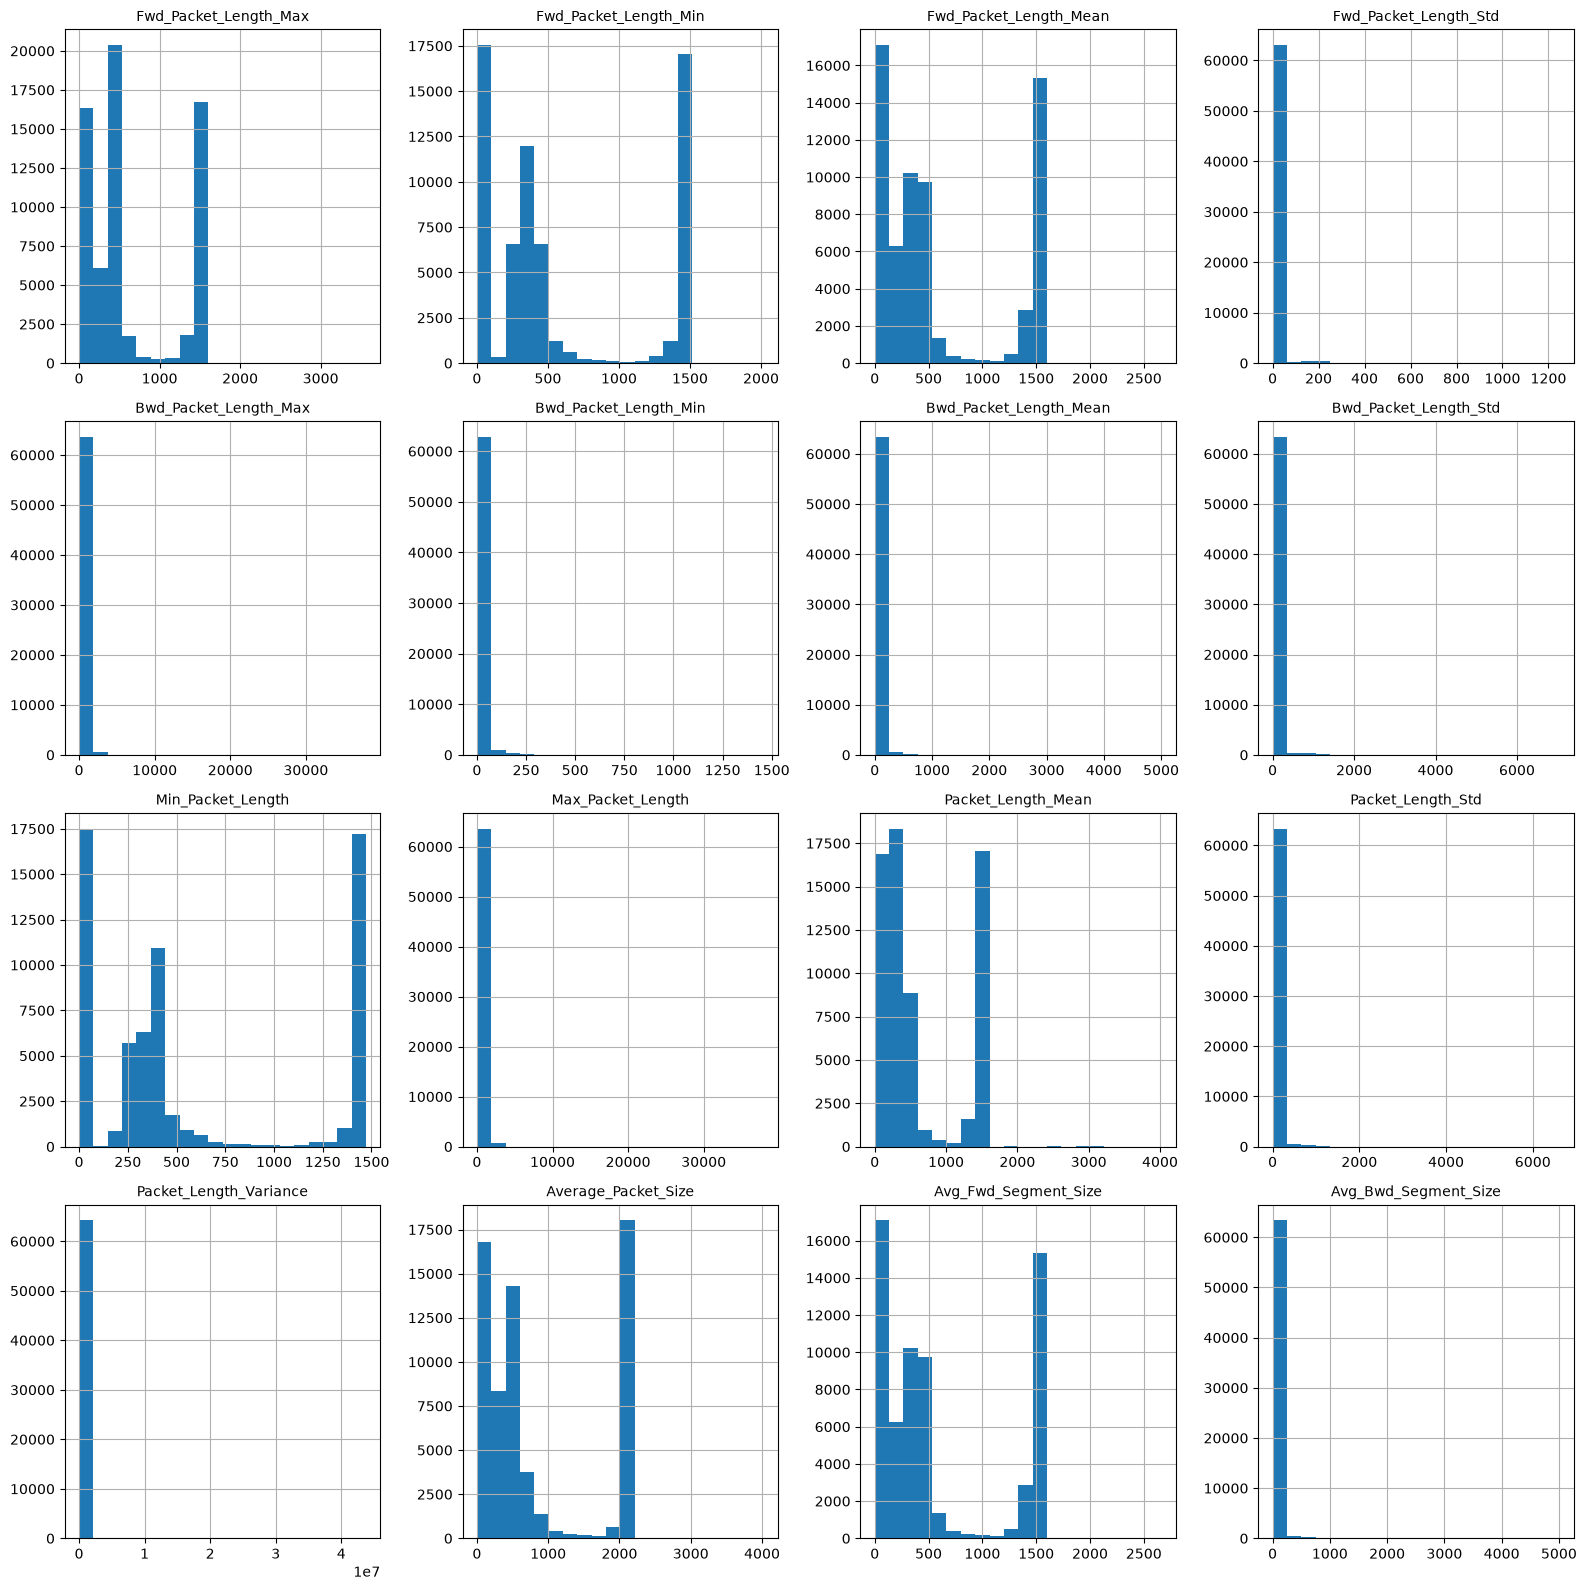

In [38]:
packet_features = " Fwd_Packet_Length_Max ,  Fwd_Packet_Length_Min ,  Fwd_Packet_Length_Mean ,  Fwd_Packet_Length_Std ,Bwd_Packet_Length_Max ,  Bwd_Packet_Length_Min ,  Bwd_Packet_Length_Mean ,  Bwd_Packet_Length_Std ,Min_Packet_Length ,  Max_Packet_Length ,  Packet_Length_Mean ,  Packet_Length_Std ,  Packet_Length_Variance,Average_Packet_Size ,  Avg_Fwd_Segment_Size ,  Avg_Bwd_Segment_Size ".replace(" ","").split(',')

df.columns = df.columns.str.strip().str.replace(" ","_")
subdf = df[packet_features]


figure,axes = plt.subplots(4,4,figsize=(16,16))

for col,ax in zip(subdf.columns,axes.flatten()):
    subdf[col].hist(ax=ax, bins=20)
    ax.set_title(col, fontsize=10)

plt.tight_layout()
plt.show()



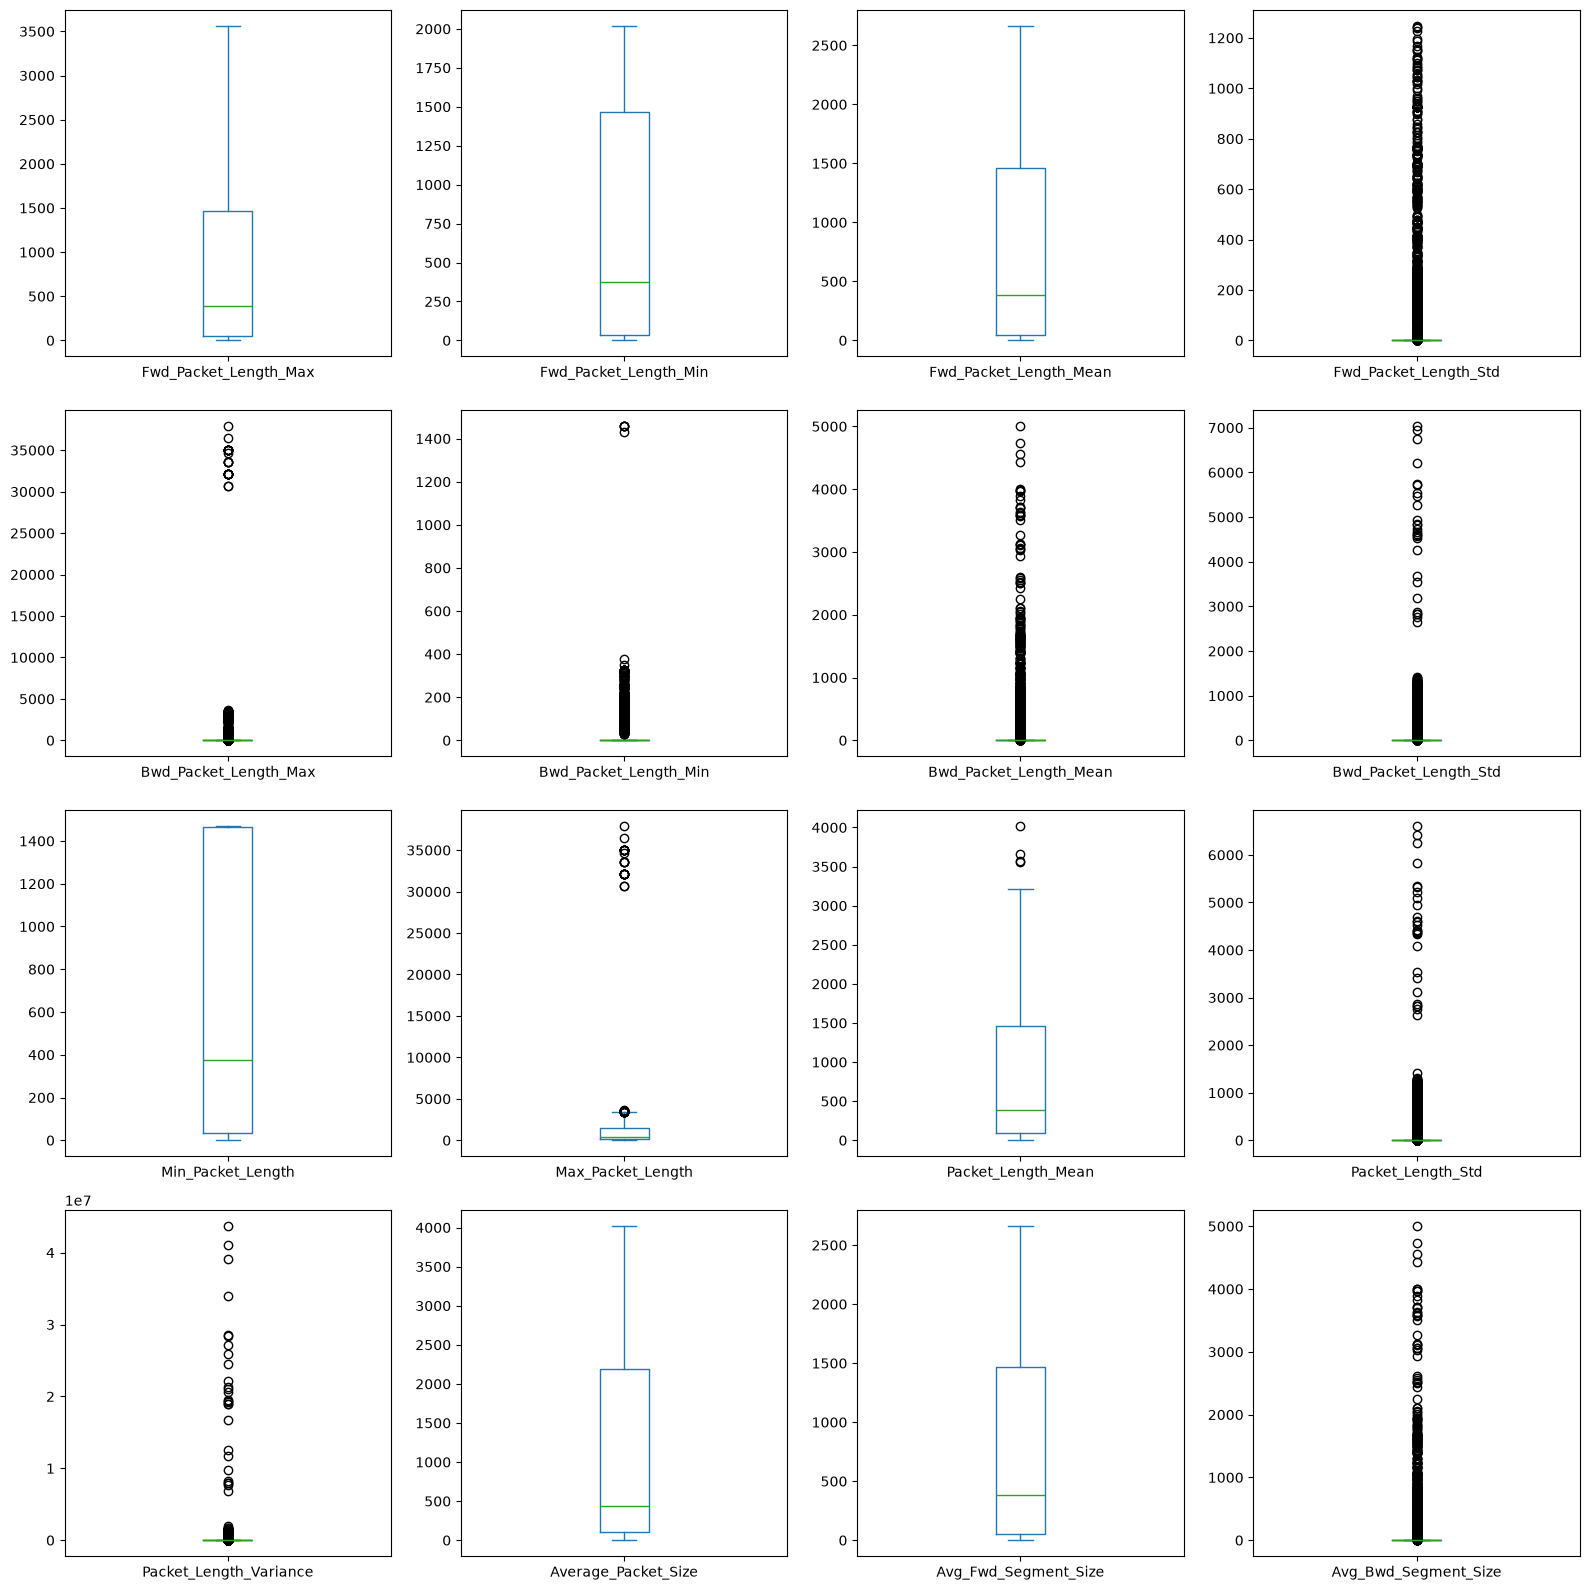

In [41]:
subdf.plot.box(subplots=True,layout=(4,4),figsize=(16,16),sharey=False)

plt.tight_layout()
plt.show()

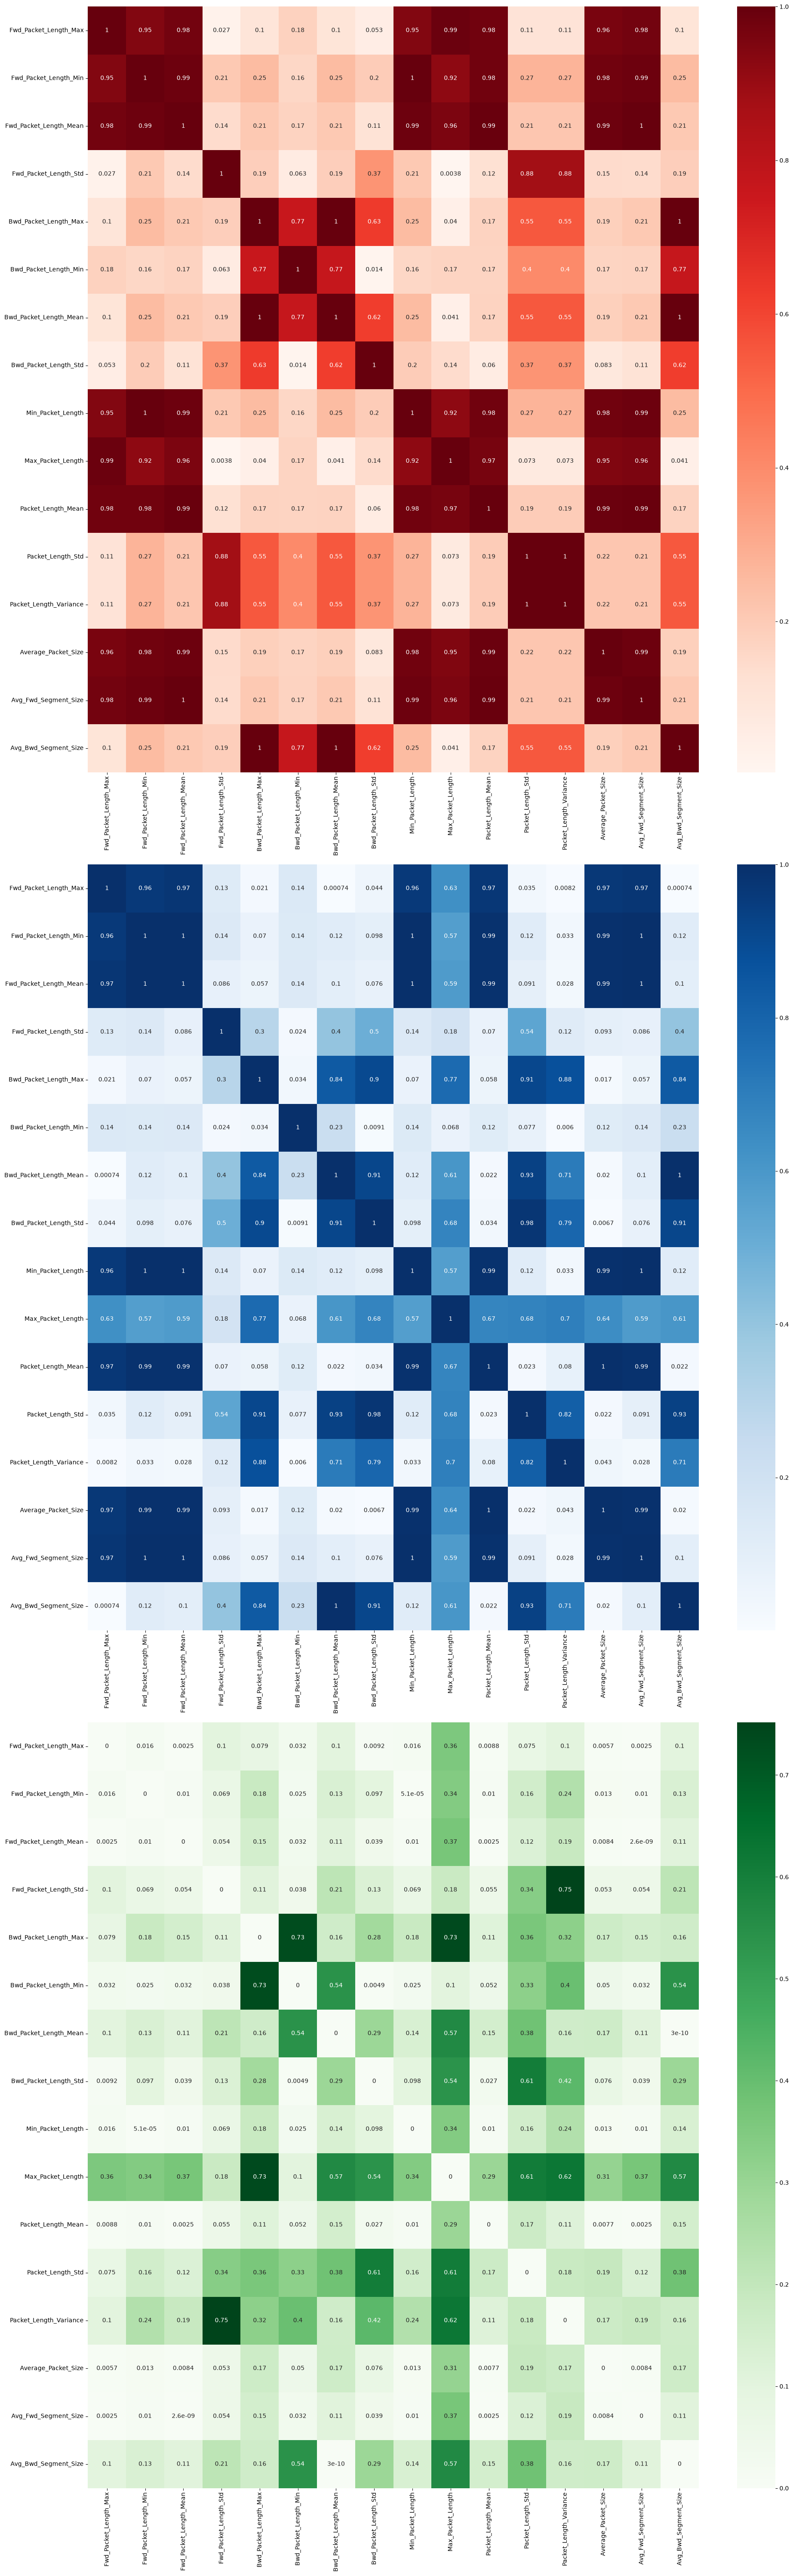

In [57]:
corr_matrix_spearman = subdf.corr(method="spearman").abs()
corr_matrix_pearson = subdf.corr(method="pearson").abs()
corr_matrix_sub = (corr_matrix_pearson - corr_matrix_spearman).abs()
figure, axes = plt.subplots(3,1,figsize=(20,60))

sns.heatmap(data=corr_matrix_spearman,cmap="Reds",annot=True, ax=axes[0])
sns.heatmap(data=corr_matrix_pearson,cmap="Blues",annot=True, ax=axes[1])
sns.heatmap(data=corr_matrix_sub, cmap="Greens", annot=True, ax=axes[2] )
plt.tight_layout()
plt.show()



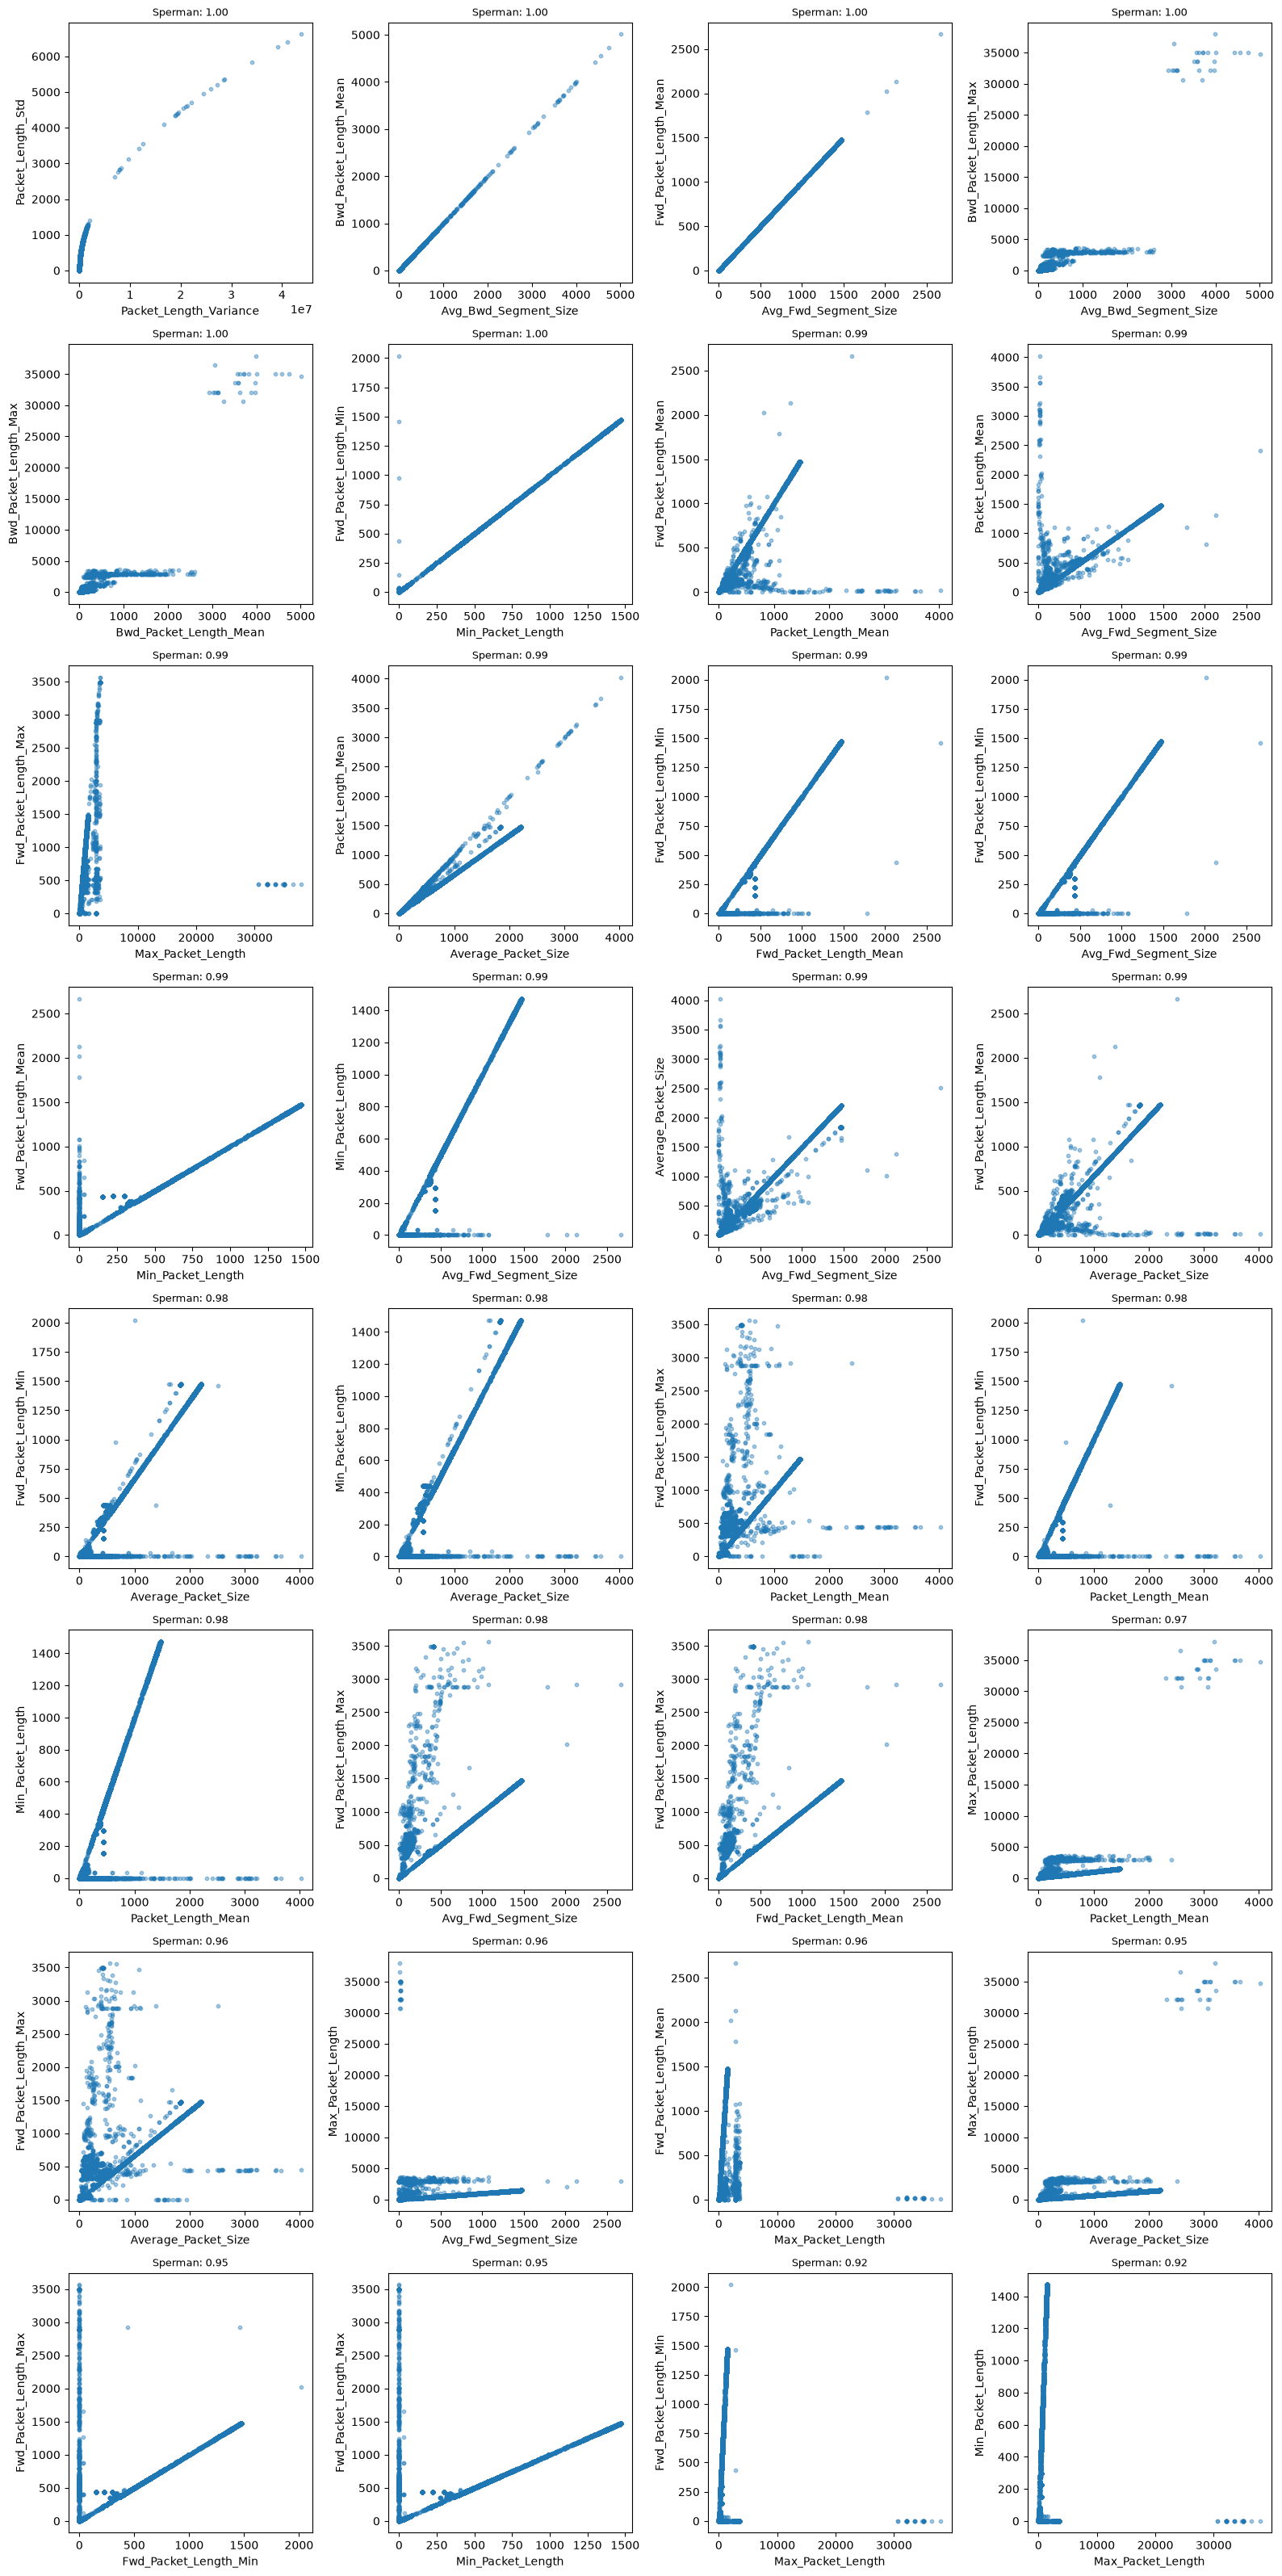

In [92]:
mask = np.triu(np.ones(corr_matrix_spearman.shape),k=1).astype(bool)

coppie_corr = corr_matrix_spearman.where(mask).unstack().dropna()
coppie_filtrate = coppie_corr[coppie_corr > 0.90].sort_values(ascending=False).reset_index()

n_cols = 4
n_couples = len(coppie_filtrate)
n_rows = int(np.ceil(n_couples/n_cols))
figure, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes_flat = np.atleast_1d(axes).flatten()

for ax,(_,row) in zip(axes_flat, coppie_filtrate.iterrows()):
    ax.scatter(x=subdf[row['level_0']],y=subdf[row['level_1']],alpha=0.4, s=10)

    ax.set_xlabel(row['level_0'])
    ax.set_ylabel(row['level_1'])
    ax.set_title(f"Sperman: {row[0]:.2f}",fontsize=9)

plt.tight_layout()
plt.show()

Packet_length_std or packet_length_variance can be removed because `pls = sqrt(plv)`
`bwd_packet_length_mean = avg_bwd_segment_size` (it can be removed)
`fwd_packet_length_mean = avg_fwd_segment_size`


In [98]:
redundances = coppie_filtrate['level_1'].unique()
subdfridotto = subdf.drop(columns=redundances)

print(subdfridotto)

       Fwd_Packet_Length_Std  Bwd_Packet_Length_Min  Bwd_Packet_Length_Std  \
0                   0.000000                    0.0                    0.0   
1                   0.000000                    0.0                    0.0   
2                   0.000000                    0.0                    0.0   
3                   0.000000                    0.0                    0.0   
4                   0.000000                    0.0                    0.0   
...                      ...                    ...                    ...   
64234               0.000000                    0.0                    0.0   
64235              35.088460                    0.0                    0.0   
64236               0.000000                    0.0                    0.0   
64237              34.063666                    0.0                    0.0   
64238               0.000000                    0.0                    0.0   

       Packet_Length_Variance  Avg_Fwd_Segment_Size  Avg_Bwd_Se

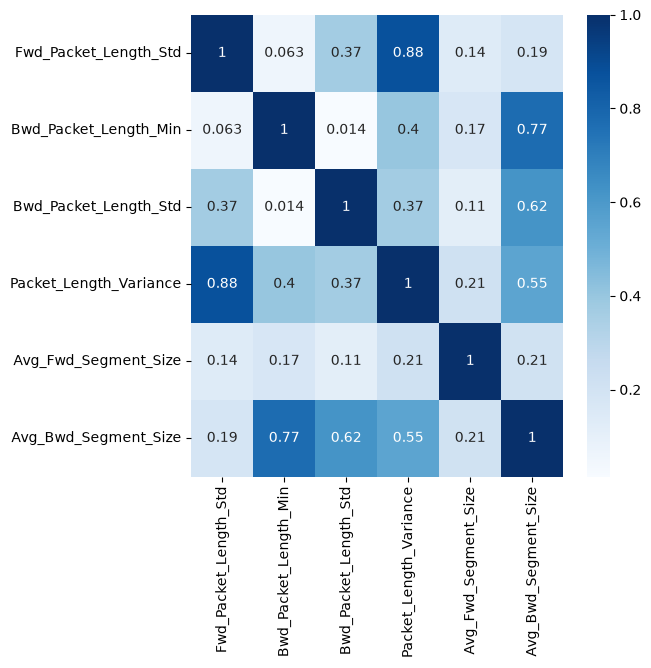

In [101]:
newcorr_matrix = subdfridotto.corr(method="spearman").abs()

plt.figure(figsize=(6,6))
sns.heatmap(data=newcorr_matrix, cmap="Blues", annot=True)
plt.show()

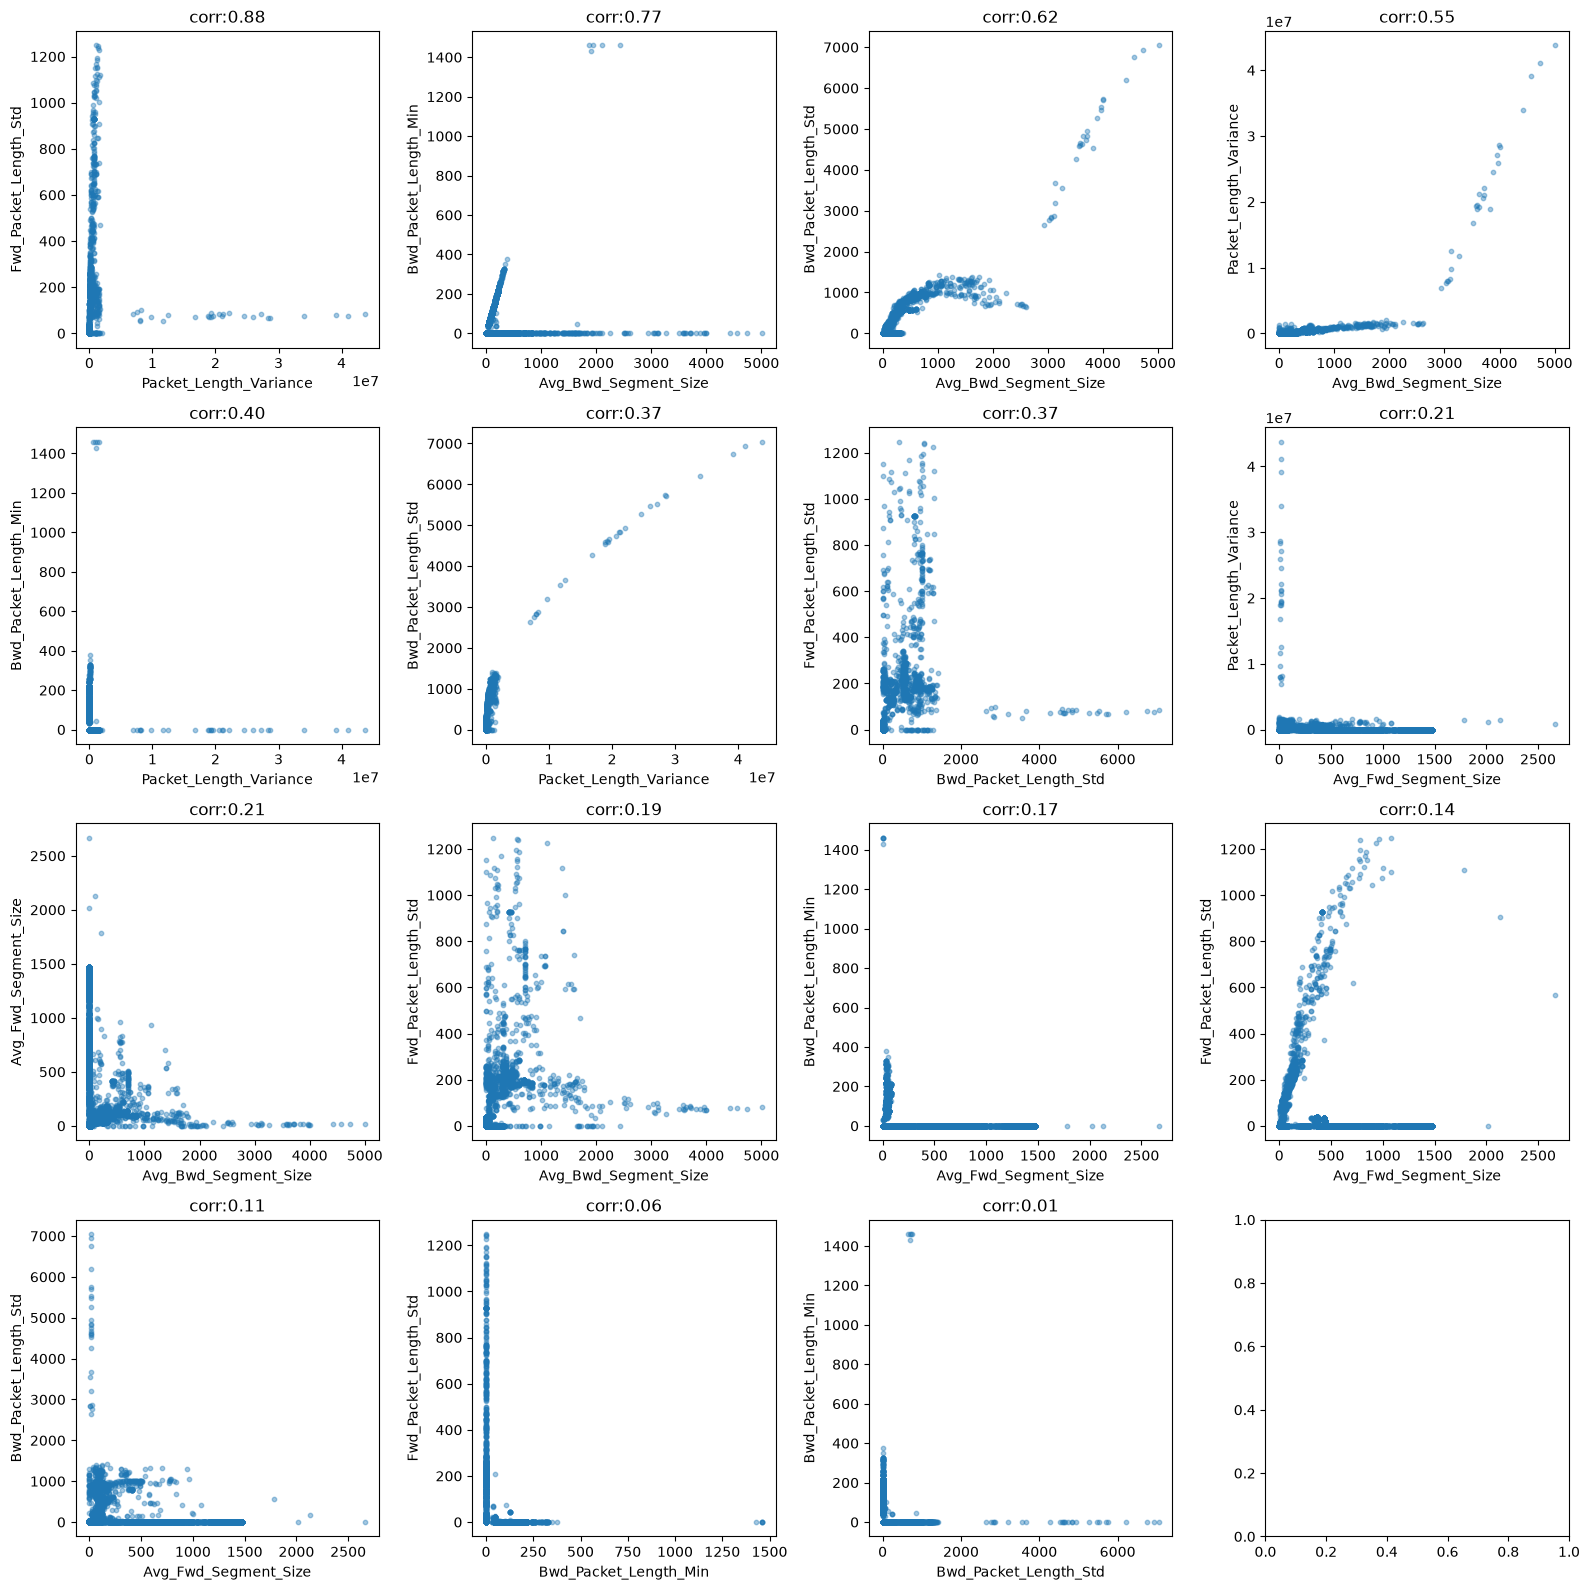

In [118]:
mask = np.triu(np.ones(newcorr_matrix.shape),k=1).astype(bool)

new_couples = newcorr_matrix.where(mask).unstack().dropna().sort_values(ascending=False).reset_index()


size = len(new_couples)
num_cols = 4
num_rows = int(np.ceil(size/num_cols))

figure, axes = plt.subplots(num_rows,num_cols,figsize=(16,16))
axes = np.atleast_1d(axes).flatten()

for ax, (_,row) in zip(axes, new_couples.iterrows()):
    x_col = subdfridotto[row['level_0']]
    y_col = subdfridotto[row['level_1']]

    ax.scatter(x_col,y_col,alpha=0.4,s=10)

    ax.set_xlabel(row['level_0'])
    ax.set_ylabel(row['level_1'])
    ax.set_title(f"corr:{row[0]:.2f}")

plt.tight_layout()
plt.show()


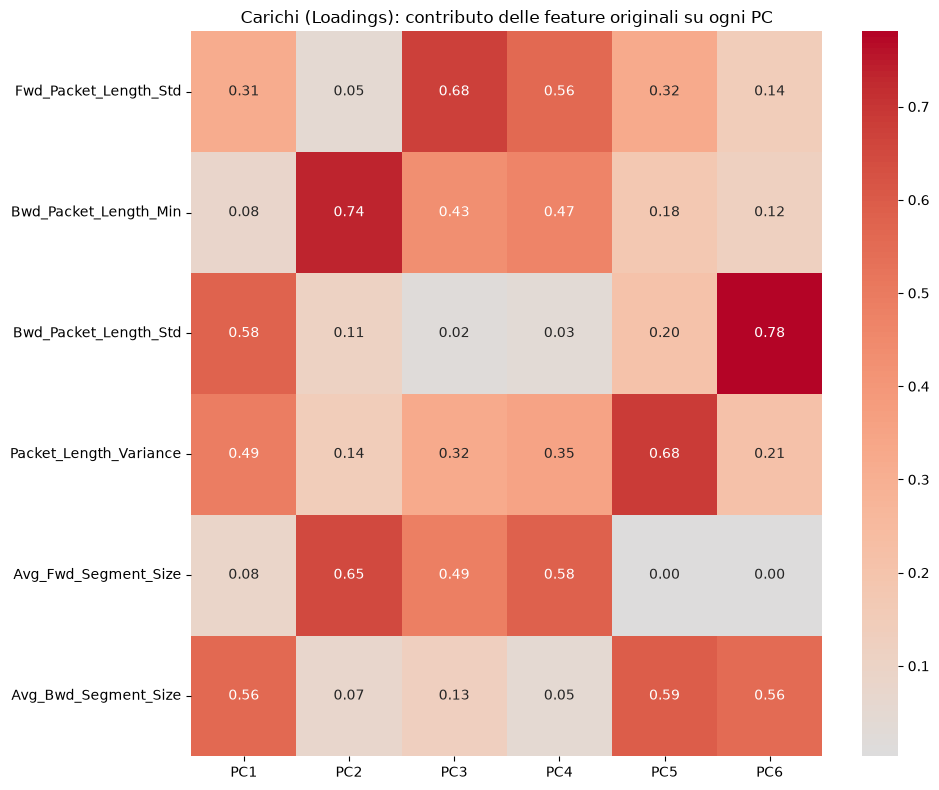

In [146]:
scaler = skp.StandardScaler()
scaled_data = scaler.fit_transform(subdfridotto)
pca = skpca.PCA(n_components=6)

subdfpca = pca.fit_transform(scaled_data)
carichi = pca.components_
er = pca.explained_variance_ratio_.sort()


pcadf = pd.DataFrame(
    data=subdfpca,
    columns=[f"PC{i}" for i in range(1,7)],
)

loadings_df = pd.DataFrame(
    data=carichi.T,
    columns=pcadf.columns,
    index=subdfridotto.columns
)
# pca_corr_matrix = pcadf.corr().abs()

# plt.figure(figsize=(16,10))
# sns.heatmap(data=pca_corr_matrix, cmap="Blues", annot=True)
# plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(loadings_df.abs(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Carichi (Loadings): contributo delle feature originali su ogni PC")
plt.tight_layout()
plt.show()




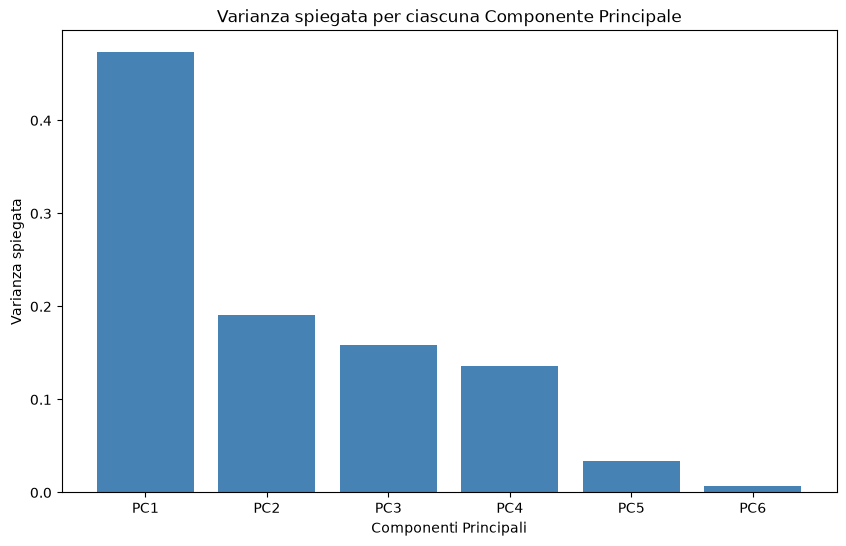

In [144]:
er = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))
plt.bar(pcadf.columns, er, color="steelblue")

plt.xlabel("Componenti Principali")
plt.ylabel("Varianza spiegata")
plt.title("Varianza spiegata per ciascuna Componente Principale")
plt.show()
